<a href="https://colab.research.google.com/github/harshkumar688/Titanic-Survival-Prediction---Data-Cleaning-Project/blob/main/Titanic_Survival_Prediction_Data_Cleaning_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [3]:
df = pd.read_csv('Titanic-Dataset.csv')

In [4]:
print("--- Dataset Information ---")
df.info()

print("\n--- Summary Statistics ---")
print(df.describe())

print("\n--- Missing Values Summary ---")
print(df.isnull().sum())

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

--- Summary Statistics ---
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.

**2. Clean Missing Data (Imputation)**

In [5]:
# Impute missing 'Age' values using Median (28.0)
df['Age'].fillna(df['Age'].median(), inplace=True)

# Impute missing 'Embarked' values using Mode ('S')
df['Embarked'].fillna(df['Embarked'].mode()[0], inplace=True)

# Drop 'Cabin' column (over 75% missing values)
df.drop(columns=['Cabin'], inplace=True)

/tmp/ipykernel_703/2975238337.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].median(), inplace=True)
/tmp/ipykernel_703/2975238337.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try 

**3. Encode Categorical Variables**

In [6]:
# Label Encoding for 'Sex' (female: 0, male: 1)
label_encoder = LabelEncoder()
df['Sex_Encoded'] = label_encoder.fit_transform(df['Sex'])

# One-Hot Encoding for 'Embarked' (Embarked_C, Embarked_Q, Embarked_S)
df = pd.get_dummies(df, columns=['Embarked'], prefix='Embarked', dtype=int)

**4. Visualize Age Distribution**

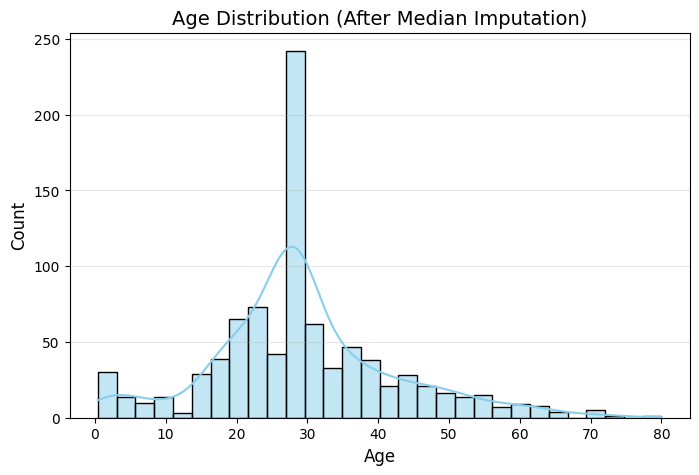

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Age'], kde=True, bins=30, color='skyblue', edgecolor='black')
plt.title('Age Distribution (After Median Imputation)', fontsize=14)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.show()

**5. Output Cleaned Dataset**

In [8]:
df.to_csv('titanic_cleaned.csv', index=False)
print("Cleaned dataset successfully saved as 'titanic_cleaned.csv'.")

Cleaned dataset successfully saved as 'titanic_cleaned.csv'.
